In [34]:
import sys
print(sys.executable)
print(sys.version)

c:\Users\siami\ENGR 418 Project\battery-life-cycle\.venv\Scripts\python.exe
3.12.4 | packaged by Anaconda, Inc. | (main, Jun 18 2024, 15:03:56) [MSC v.1929 64 bit (AMD64)]


imports and project paths

In [35]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import yaml

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

from soc.data import split_frames
from soc.features import feature_columns
from soc.metrics import soc_metrics
from soc.models import FNN

print("project root:", ROOT)

project root: c:\Users\siami\ENGR 418 Project\battery-life-cycle


In [36]:
cfg = yaml.safe_load(open(ROOT / "configs" / "default.yaml"))
data = pd.read_parquet(ROOT / cfg["processed_path"])
splits = split_frames(data, cfg["split"])

for name, df in splits.items():
    print(f"{name:5s}: {df.run_id.nunique()} runs, {len(df):,} rows")

train: 36 runs, 231,428 rows
val  : 5 runs, 35,728 rows
test : 23 runs, 175,874 rows


In [37]:
MODEL_DIR = ROOT / "outputs" / "fnn" / "seed42"
ckpt = torch.load(MODEL_DIR / "model.pt", map_location="cpu", weights_only=False)

cols = ckpt["features"]
mean = np.asarray(ckpt["scaler"]["mean"])
std = np.asarray(ckpt["scaler"]["std"])
mcfg = ckpt["config"]

model = FNN(len(cols), mcfg["hidden"], mcfg.get("dropout", 0))
model.load_state_dict(ckpt["state_dict"])
model.eval()

print("features:", cols)
print("hidden layers:", mcfg["hidden"])

features: ['voltage', 'current', 'temp_c', 'v_avg_30s', 'i_avg_30s', 'v_avg_120s', 'i_avg_120s', 'v_avg_300s', 'i_avg_300s']
hidden layers: [64, 64, 32]


In [38]:
def predict_array(x):
    x = (x - mean) / std
    x = torch.tensor(x, dtype=torch.float32)
    with torch.no_grad():
        return model(x).numpy().reshape(-1)

def predict(df):
    return predict_array(df[cols].to_numpy())

test = splits["test"].copy()
test["soc_pred"] = predict(test)
test["err"] = (test["soc_pred"] - test["soc"]) * 100
test["abs_err"] = test["err"].abs()
test["t_min"] = test["time_s"] / 60

test[["run_id", "t_min", "soc", "soc_pred", "err"]].head()

,run_id,t_min,soc,soc_pred,err
0,n20degC_610_HWFET,0.000000,0.999982,0.991996,-0.798612
1,n20degC_610_HWFET,0.016667,0.999970,0.991038,-0.893200
2,n20degC_610_HWFET,0.033333,0.999952,0.990255,-0.969755
3,n20degC_610_HWFET,0.050000,0.999916,0.989110,-1.080606
4,n20degC_610_HWFET,0.066667,0.999779,0.985971,-1.380783


In [39]:
import json

saved = json.load(open(MODEL_DIR / "metrics.json"))

for t, g in test.groupby("ambient_c"):
    now = soc_metrics(g["soc"], g["soc_pred"])["rmse_pct"]
    before = saved["test_by_temp"][str(t)]["rmse_pct"]
    print(f"{t:>4} °C   now {now:.3f}   saved {before:.3f}")

overall = soc_metrics(test["soc"], test["soc_pred"])["rmse_pct"]
print(f"overall  now {overall:.3f}   saved {saved['test']['rmse_pct']:.3f}")


 -20 °C   now 3.380   saved 3.380


 -10 °C   now 2.253   saved 2.253
   0 °C   now 1.456   saved 1.456
  10 °C   now 1.456   saved 1.456
  25 °C   now 1.602   saved 1.602
  40 °C   now 1.503   saved 1.503
overall  now 1.928   saved 1.928


In [40]:
#confirming the sampling period (data check)
step_s = 1 / cfg["resample_hz"]
print("configured sample period:", step_s, "s")

gaps = test.groupby("run_id")["time_s"].diff().dropna()
print(gaps.value_counts().head())

configured sample period: 1.0 s
time_s
1.0     175820
2.0         29
16.0         1
4.0          1
Name: count, dtype: int64


Section 1: where in the run does the error happen?

In [41]:
def label_segments(df, rest_current=0.05, min_rest_s=60):
    """Split each run into: early 0-5 min, early 5-10 min, middle, rest tail.

    rest tail = final stretch after the last |current| > rest_current,
                counted only if it lasts at least min_rest_s seconds.
    """
    segment = pd.Series("middle", index=df.index)
    for run_id, g in df.groupby("run_id"):
        moving = g[g["current"].abs() > rest_current]
        if moving.empty:
            print(f"WARNING: {run_id} never exceeds {rest_current} A - no rest tail assigned")
            is_rest = pd.Series(False, index=g.index)
        else:
            last_moving_time = moving["time_s"].max()
            is_rest = g["time_s"] > last_moving_time
            rest_duration = g["time_s"].max() - last_moving_time
            if rest_duration < min_rest_s:
                is_rest[:] = False          # too short to count as a rest period
        segment.loc[g.index[is_rest]] = "rest tail"
        segment.loc[g.index[(~is_rest) & (g["t_min"] < 10)]] = "early 5-10"
        segment.loc[g.index[(~is_rest) & (g["t_min"] < 5)]] = "early 0-5"
    return segment

test["segment"] = label_segments(test)
test["segment"].value_counts()

segment
middle        148292
rest tail      13800
early 5-10      6900
early 0-5       6882
Name: count, dtype: int64

In [42]:
#Checking the final resting period (rest tail) of each battery test run to see:
#1. How many data points are in the resting period.
#2. What the maximum absolute current is during that period.
#3. How much the battery's State of Charge (SOC) changes during that period.
#4. Which battery runs do not have a detected resting period.

tail = test[test["segment"] == "rest tail"]
check_tail = tail.groupby("run_id").agg(
    tail_samples=("time_s", "size"),
    tail_start_s=("time_s", "min"),
    tail_end_s=("time_s", "max"),
    max_abs_current=("current", lambda s: s.abs().max()),
    soc_change_pts=("soc", lambda s: (s.max() - s.min()) * 100),
)
check_tail["tail_duration_s"] = check_tail["tail_end_s"] - check_tail["tail_start_s"] + step_s
check_tail["missing_samples"] = check_tail["tail_duration_s"] / step_s - check_tail["tail_samples"]

print(check_tail.drop(columns=["tail_start_s", "tail_end_s"]).round(3).to_string())
print("\nruns with no rest tail:", sorted(set(test["run_id"]) - set(check_tail.index)))

                   tail_samples  max_abs_current  soc_change_pts  tail_duration_s  missing_samples
run_id                                                                                            
0degC_589_HWFET             600              0.0             0.0            600.0              0.0
0degC_589_LA92              600              0.0             0.0            600.0              0.0
0degC_589_UDDS              600              0.0             0.0            600.0              0.0
0degC_589_US06              600              0.0             0.0            600.0              0.0
10degC_567_US06             600              0.0             0.0            600.0              0.0
10degC_576_HWFET            600              0.0             0.0            600.0              0.0
10degC_576_UDDS             600              0.0             0.0            600.0              0.0
10degC_582_LA92             600              0.0             0.0            600.0              0.0
25degC_551

In [43]:
#Error per segment, cold vs warm ambient temperature

ORDER = ["early 0-5", "early 5-10", "middle", "rest tail"]
rows = []
for t, g in test.groupby("ambient_c"):
    total_sq = (g["err"] ** 2).sum()
    for s in ORDER:
        h = g[g["segment"] == s]
        rows.append({
            "ambient_c": t,
            "segment": s,
            "minutes": len(h) * step_s / 60,
            "rmse": np.sqrt((h["err"] ** 2).mean()),
            "mean_signed": h["err"].mean(),
            "share_%": 100 * (h["err"] ** 2).sum() / total_sq,
        })
seg = pd.DataFrame(rows)

def show(value, title, digits=2):
    print(title)
    print(seg.pivot(index="ambient_c", columns="segment", values=value)[ORDER].round(digits))
    print()

show("rmse", "RMSE per segment (SOC points)")
show("share_%", "Share of each temperature's total squared error (%)", 1)
show("mean_signed", "Mean signed error (+ = over-estimate, - = under-estimate)")
show("minutes", "Minutes of data per segment (all test runs at that temperature)", 0)

RMSE per segment (SOC points)
segment    early 0-5  early 5-10  middle  rest tail
ambient_c                                          
-20             8.30        4.91    2.53       2.67
-10             3.47        3.13    2.14       1.95
 0              2.40        2.06    1.41       0.80
 10             2.16        1.97    1.40       1.37
 25             2.03        1.43    1.59       1.62
 40             2.69        2.22    1.42       1.28

Share of each temperature's total squared error (%)
segment    early 0-5  early 5-10  middle  rest tail
ambient_c                                          
-20             37.0        13.0    42.3        7.7
-10             10.4         8.5    74.5        6.6
 0              10.7         7.9    79.1        2.3
 10              7.8         6.6    79.2        6.4
 25              4.8         2.4    86.7        6.1
 40             10.8         7.4    76.9        4.9

Mean signed error (+ = over-estimate, - = under-estimate)
segment    early 0-5  earl

In [44]:
#voltage relaxation vs prediction drift during rest
#Voltage relaxation: How much voltage changes during zero-current rest.
#Prediction stability: Whether your FNN predicts SOC changes when actual SOC is constant.
#Temperature dependence: Whether this behaviour is more pronounced at −20°C and −10°C than at warmer temperatures.

rows = []
rest = test[test["segment"] == "rest tail"]
for run_id, g in rest.groupby("run_id"):
    g = g.sort_values("time_s")
    drift = (g["soc_pred"].iloc[-1] - g["soc_pred"].iloc[0]) * 100
    rows.append({
        "run_id": run_id,
        "ambient_c": g["ambient_c"].iloc[0],
        "v_rise_mV": (g["voltage"].iloc[-1] - g["voltage"].iloc[0]) * 1000,
        "pred_drift_pts": drift,
        "abs_pred_drift_pts": abs(drift),
    })
relax = pd.DataFrame(rows).sort_values(["ambient_c", "run_id"])

print(relax.round(2).to_string(index=False))
print("\nAverage per temperature:")
print(relax.groupby("ambient_c")[["v_rise_mV", "pred_drift_pts", "abs_pred_drift_pts"]].mean().round(2))
print("\nCorrelation between voltage rise and prediction drift:",
      round(relax["v_rise_mV"].corr(relax["pred_drift_pts"]), 2))

           run_id  ambient_c  v_rise_mV  pred_drift_pts  abs_pred_drift_pts
n20degC_610_HWFET        -20     480.77            3.55                3.55
 n20degC_610_LA92        -20     318.97            0.27                0.27
 n20degC_610_UDDS        -20     170.32            0.95                0.95
 n20degC_610_US06        -20     451.41            0.28                0.28
n10degC_596_HWFET        -10     275.12            2.61                2.61
 n10degC_596_LA92        -10     271.81            0.29                0.29
 n10degC_596_UDDS        -10     110.94            0.51                0.51
 n10degC_601_US06        -10     320.68           -0.51                0.51
  0degC_589_HWFET          0     263.89           -1.09                1.09
   0degC_589_LA92          0     172.39           -1.80                1.80
   0degC_589_UDDS          0      60.56           -0.65                0.65
   0degC_589_US06          0     350.46           -1.10                1.10
  10degC_567

how does the model’s error change minute by minute from the start of a run, and how does that differ by temperature?

The three graphs and the table below each have a role:
-Cold vs 25 °C: compares -20,-10,0 temp against room temp.
-Warm vs 25 °C: compares 10,40 temp against room temp.
-All six: the overall trend comparison.
-Table (first 5 min vs 5–60 min, plus ratio): error comparison

In [45]:
#setup for plotting error curves

temps = sorted(test["ambient_c"].unique())
color_of = dict(zip(temps, plt.cm.coolwarm(np.linspace(0, 1, len(temps)))))
REF = 25
FIG_DIR = ROOT / "outputs" / "diagnosis"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def error_curve(t):
    """Rows for one temperature (no rest tail, first 60 min) and mean |error| per 1-min bin."""
    g = test[
        (test["ambient_c"] == t)
        & (test["segment"] != "rest tail")
        & (test["t_min"] < 60)
    ]
    return g, g.groupby(g["t_min"].floordiv(1))["abs_err"].mean()

# one y-axis range shared by all three graphs, so they can be compared fairly
Y_MAX = max(error_curve(t)[1].max() for t in temps) * 1.05

def plot_temps(panel_temps, title, filename, ref_dashed=True):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for t in panel_temps:
        _, binned = error_curve(t)
        dashed = ref_dashed and t == REF
        ax.plot(binned.index, binned.values, color=color_of[t],
                lw=2.2 if t < 0 else 1.4, ls="--" if dashed else "-", label=f"{t} °C")
    ax.axvspan(0, 5, color="grey", alpha=0.15, label="300 s window filling")
    ax.set_ylim(0, Y_MAX)
    ax.set_xlabel("time from start of run (min)")
    ax.set_ylabel("mean |error| (SOC points)")
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)
    fig.tight_layout()
    fig.savefig(FIG_DIR / filename, dpi=150)
    plt.show()

print("shared y-axis max:", round(Y_MAX, 2))

shared y-axis max: 8.07


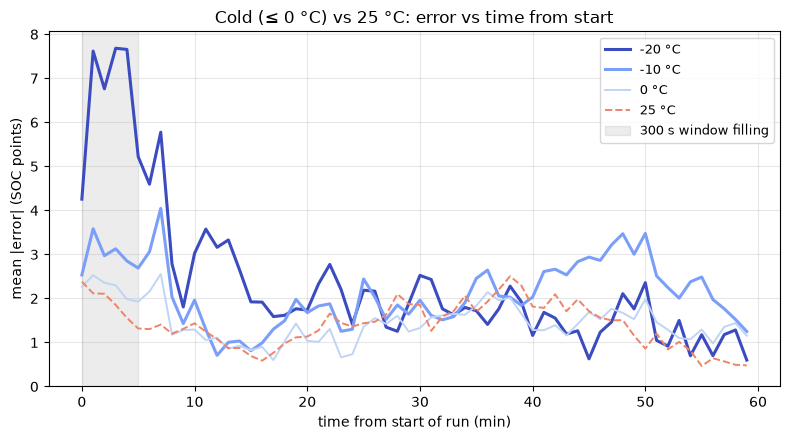

In [46]:
#graph 1, cold vs 25 °C

plot_temps([-20, -10, 0, REF],
           "Cold (≤ 0 °C) vs 25 °C: error vs time from start",
           "error_vs_time_cold.png")

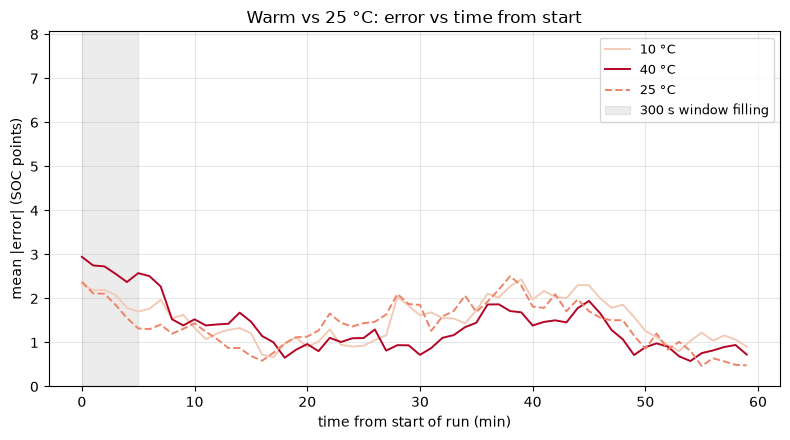

In [47]:
#graph 2, warm vs 25 °C

plot_temps([10, 40, REF],
           "Warm vs 25 °C: error vs time from start",
           "error_vs_time_warm.png")

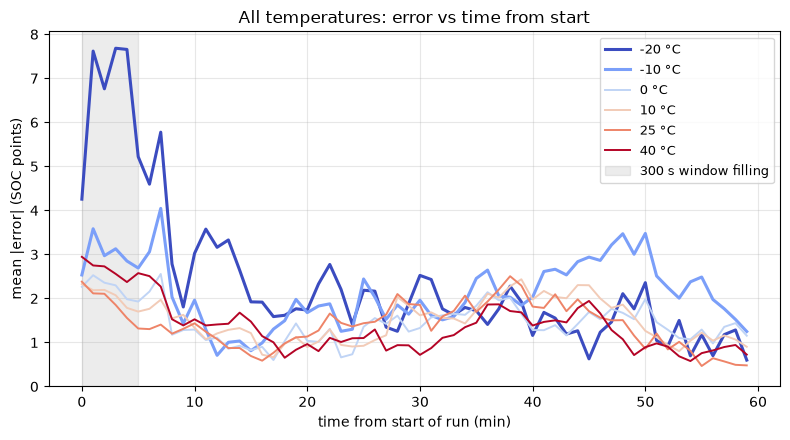

In [48]:
#graph 3, all six temperatures

plot_temps(temps,
           "All temperatures: error vs time from start",
           "error_vs_time_all.png",
           ref_dashed=False)

In [49]:
# Summary of MAE for early vs. later time periods

summary = []
for t in temps:
    g, _ = error_curve(t)
    early_mae = g.loc[g["t_min"] < 5, "abs_err"].mean()
    later_mae = g.loc[g["t_min"] >= 5, "abs_err"].mean()
    summary.append({"ambient_c": t,
                    "MAE first 5 min": early_mae,
                    "MAE 5-60 min": later_mae,
                    "ratio early/later": early_mae / later_mae})
early_vs_later = pd.DataFrame(summary).set_index("ambient_c")
print(early_vs_later.round(3))

           MAE first 5 min  MAE 5-60 min  ratio early/later
ambient_c                                                  
-20                  6.795         2.114              3.214
-10                  3.013         2.011              1.498
 0                   2.286         1.387              1.649
 10                  2.109         1.475              1.430
 25                  2.002         1.377              1.454
 40                  2.671         1.263              2.115
